# 04 — Exploratory Data Analysis & Business Analysis

## Objective
Explore the integrated Olist e-commerce dataset to understand sales performance, customer purchasing behavior, product category performance, delivery efficiency, payment patterns, and customer satisfaction.

## Dataset
The analysis uses the integrated master dataset created during the data integration and feature engineering stage.

## Tools
- Python
- Pandas
- Matplotlib
- Seaborn

## Approach
Inspect the dataset, analyze key business metrics, identify patterns and anomalies, and communicate findings through visualizations and evidence-based conclusions.

In [51]:

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

# Load the integrated dataset
df = pd.read_csv(
    "../cleaned_data/olist_master_dataset.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Shape: (110697, 39)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,item_total_value,freight_percentage,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,approval_delay_hours,delivery_difference_days,delivery_status,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,product_category_name,product_name_length,product_description_length,product_photos_qty,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_city,seller_state,total_payment_value,payment_count,avg_review_score,review_count,avg_review_response_days
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,72.19,22.56,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,7.61,0.78,-8.01,Early / On Time,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,cool_stuff,58.00,598.00,4.00,28.00,9.00,14.00,cool_stuff,volta redonda,SP,72.19,1.00,5.00,1.00,1.46
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,259.83,8.31,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,16.22,0.20,-2.33,Early / On Time,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,SP,pet_shop,56.00,239.00,2.00,50.00,30.00,40.00,pet_shop,sao paulo,SP,259.83,1.00,4.00,1.00,2.48
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,216.87,8.98,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,7.95,0.25,-13.44,Early / On Time,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG,moveis_decoracao,59.00,695.00,2.00,33.00,13.00,33.00,furniture_decor,borda da mata,MG,216.87,1.00,5.00,1.00,0.67
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,25.78,98.46,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,6.15,0.16,-5.44,Early / On Time,af861d436cfc08b2c2ddefd0ba074622,12952,atibaia,SP,perfumaria,42.00,480.00,1.00,16.00,10.00,15.00,perfumery,franca,SP,25.78,1.00,4.00,1.00,0.69
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,218.04,9.07,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,25.11,0.21,-15.30,Early / On Time,64b576fb70d441e8f1b2d7d446e483c5,13226,varzea paulista,SP,ferramentas_jardim,59.00,409.00,1.00,35.00,40.00,30.00,garden_tools,loanda,PR,218.04,1.00,5.00,1.00,1.45


In [52]:

# Step 3: Inspect data quality

print("DATASET INFORMATION")
print("=" * 40)
df.info()

print("\nMISSING VALUES")
print("=" * 40)
missing = df.isna().sum()
print(missing[missing > 0].sort_values(ascending=False))

print("\nORDER STATUS COUNTS")
print("=" * 40)
print(df["order_status"].value_counts(dropna=False))

print("\nPURCHASE DATE RANGE")
print("=" * 40)
print("Earliest:", df["order_purchase_timestamp"].min())
print("Latest:", df["order_purchase_timestamp"].max())


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 110697 entries, 0 to 110696
Data columns (total 39 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       110697 non-null  str    
 1   order_item_id                  110697 non-null  int64  
 2   product_id                     110697 non-null  str    
 3   seller_id                      110697 non-null  str    
 4   shipping_limit_date            110697 non-null  str    
 5   price                          110697 non-null  float64
 6   freight_value                  110697 non-null  float64
 7   item_total_value               110697 non-null  float64
 8   freight_percentage             110697 non-null  float64
 9   customer_id                    110697 non-null  str    
 10  order_status                   110697 non-null  str    
 11  order_purchase_timestamp       110697 non-null  str    
 12  order_approved_at    

In [53]:
# Step 4: Convert date columns to datetime

date_columns = [
    "shipping_limit_date",
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    df[column] = pd.to_datetime(df[column], errors="coerce")

print("Date conversion completed.")

print("\nDate column data types:")
print(df[date_columns].dtypes)

print("\nPurchase date range:")
print("Earliest:", df["order_purchase_timestamp"].min())
print("Latest:", df["order_purchase_timestamp"].max())

print("\nMissing values after date conversion:")
print(df[date_columns].isna().sum())

Date conversion completed.

Date column data types:
shipping_limit_date              datetime64[us]
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

Purchase date range:
Earliest: 2016-09-04 21:15:19
Latest: 2018-09-03 09:06:57

Missing values after date conversion:
shipping_limit_date                 0
order_purchase_timestamp            0
order_approved_at                  14
order_delivered_carrier_date     1190
order_delivered_customer_date    2375
order_estimated_delivery_date       0
dtype: int64


In [54]:
# Step 5: Calculate core business metrics

total_order_items = len(df)
unique_orders = df["order_id"].nunique()
unique_customers = df["customer_unique_id"].nunique()
unique_products = df["product_id"].nunique()
unique_sellers = df["seller_id"].nunique()

total_product_sales = df["price"].sum()
total_freight = df["freight_value"].sum()
total_sales_with_freight = df["item_total_value"].sum()

delivered_order_ids = df.loc[
    df["order_status"] == "delivered",
    "order_id"
].nunique()

order_values = (
    df.groupby("order_id", as_index=False)
      .agg(order_value=("item_total_value", "sum"))
)

average_order_value = order_values["order_value"].mean()

print("CORE BUSINESS METRICS")
print("=" * 40)
print(f"Total order items: {total_order_items:,}")
print(f"Unique orders: {unique_orders:,}")
print(f"Unique customers: {unique_customers:,}")
print(f"Unique products: {unique_products:,}")
print(f"Unique sellers: {unique_sellers:,}")
print(f"Delivered orders: {delivered_order_ids:,}")
print(f"Product sales: {total_product_sales:,.2f}")
print(f"Freight charges: {total_freight:,.2f}")
print(f"Sales including freight: {total_sales_with_freight:,.2f}")
print(f"Average order value: {average_order_value:,.2f}")

CORE BUSINESS METRICS
Total order items: 110,697
Unique orders: 96,897
Unique customers: 93,765
Unique products: 31,058
Unique sellers: 3,036
Delivered orders: 94,786
Product sales: 13,232,495.02
Freight charges: 2,210,203.99
Sales including freight: 15,442,699.01
Average order value: 159.37


In [55]:
# Step 6: Monthly sales analysis

# Ensure purchase timestamps are in datetime format
df["order_purchase_timestamp"] = pd.to_datetime(
    df["order_purchase_timestamp"],
    errors="coerce"
)

# Keep delivered orders only
delivered_df = df[df["order_status"] == "delivered"].copy()

# Extract the purchase month
delivered_df["purchase_month"] = (
    delivered_df["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Calculate monthly sales
monthly_sales = (
    delivered_df.groupby("purchase_month")
    .agg(
        total_sales=("item_total_value", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

# Display the results
print("MONTHLY SALES SUMMARY")
display(monthly_sales)

MONTHLY SALES SUMMARY


,purchase_month,total_sales,total_orders
0,2016-09,143.46,1
1,2016-10,"45,099.16",253
2,2016-12,19.62,1
3,2017-01,"122,852.27",728
4,2017-02,"262,926.17",1614
5,2017-03,"402,739.08",2489
6,2017-04,"378,343.41",2269
7,2017-05,"554,333.20",3486
8,2017-06,"483,079.44",3104
9,2017-07,"554,422.38",3819


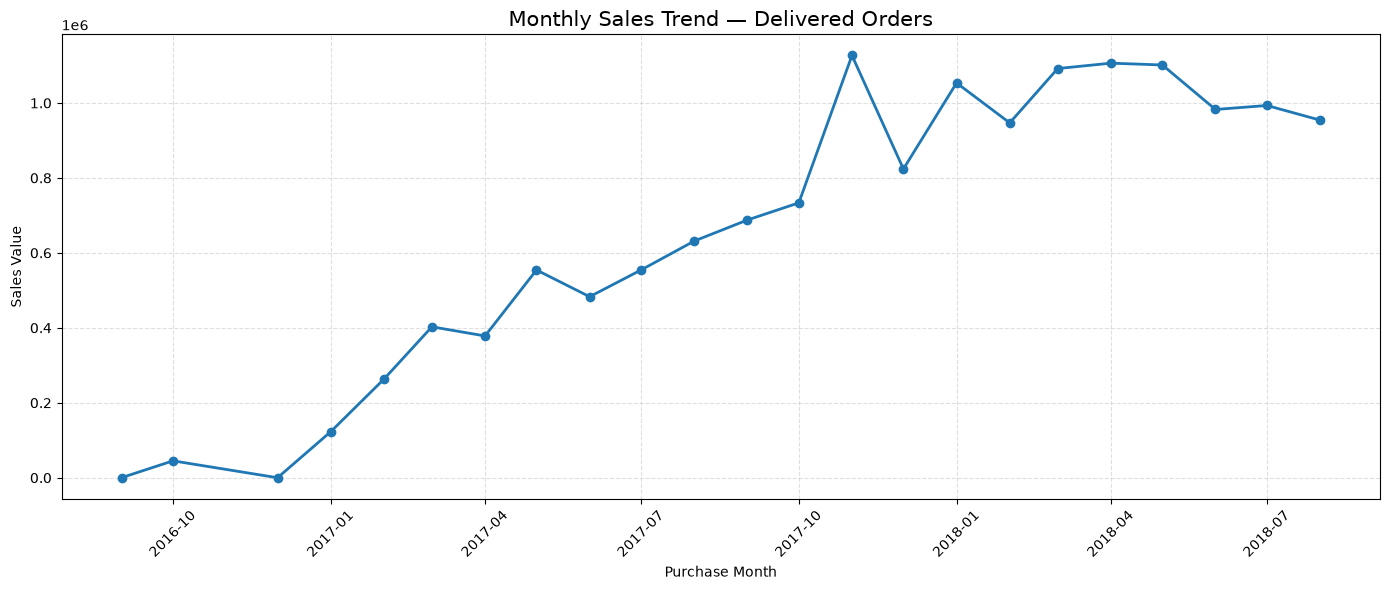

In [56]:
# Step 7: Visualize monthly sales trends

# Convert monthly periods into dates for plotting
monthly_sales["month_date"] = (
    monthly_sales["purchase_month"].dt.to_timestamp()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["month_date"],
    monthly_sales["total_sales"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend — Delivered Orders", fontsize=15)
plt.xlabel("Purchase Month")
plt.ylabel("Sales Value")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [57]:
# Step 8: Monthly orders and average order value

monthly_orders = (
    delivered_df.groupby("purchase_month")
    .agg(
        total_orders=("order_id", "nunique"),
        total_sales=("item_total_value", "sum")
    )
    .reset_index()
)

monthly_orders["average_order_value"] = (
    monthly_orders["total_sales"]
    / monthly_orders["total_orders"]
)

display(monthly_orders)

,purchase_month,total_orders,total_sales,average_order_value
0,2016-09,1,143.46,143.46
1,2016-10,253,"45,099.16",178.26
2,2016-12,1,19.62,19.62
3,2017-01,728,"122,852.27",168.75
4,2017-02,1614,"262,926.17",162.90
5,2017-03,2489,"402,739.08",161.81
6,2017-04,2269,"378,343.41",166.74
7,2017-05,3486,"554,333.20",159.02
8,2017-06,3104,"483,079.44",155.63
9,2017-07,3819,"554,422.38",145.17


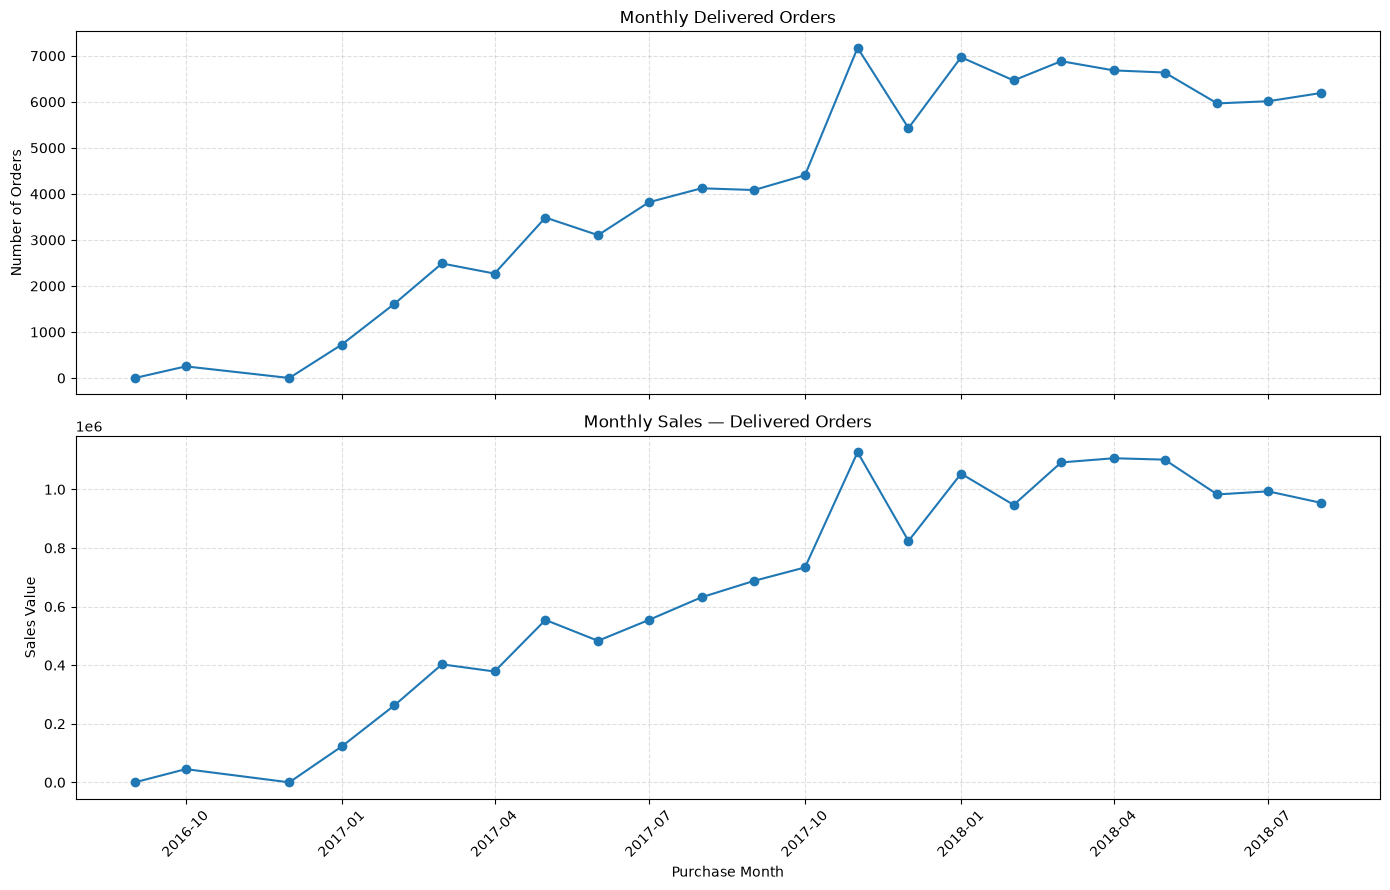

In [58]:
# Step 9: Visualize monthly orders and sales

monthly_orders["month_date"] = (
    monthly_orders["purchase_month"].dt.to_timestamp()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Monthly order volume
axes[0].plot(
    monthly_orders["month_date"],
    monthly_orders["total_orders"],
    marker="o"
)
axes[0].set_title("Monthly Delivered Orders")
axes[0].set_ylabel("Number of Orders")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Monthly sales
axes[1].plot(
    monthly_orders["month_date"],
    monthly_orders["total_sales"],
    marker="o"
)
axes[1].set_title("Monthly Sales — Delivered Orders")
axes[1].set_xlabel("Purchase Month")
axes[1].set_ylabel("Sales Value")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [59]:
# Step 10: Sales by product category

# Keep delivered orders with a known English product category
category_df = delivered_df.dropna(
    subset=["product_category_name_english"]
).copy()

# Group sales and orders by product category
category_sales = (
    category_df.groupby("product_category_name_english")
    .agg(
        total_sales=("item_total_value", "sum"),
        total_orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count")
    )
    .reset_index()
)

# Sort from highest to lowest sales
category_sales = category_sales.sort_values(
    by="total_sales",
    ascending=False
)

# Display the top 10 categories
display(category_sales.head(10))

,product_category_name_english,total_sales,total_orders,items_sold
43,health_beauty,"1,316,839.10",8105,8882
72,watches_gifts,"1,140,424.00",5153,5497
7,bed_bath_table,"1,125,740.89",8590,10101
66,sports_leisure,"1,028,951.13",6994,7819
15,computers_accessories,"948,878.78",6123,7182
71,unknown,"828,890.83",5313,5857
39,furniture_decor,"806,289.97",5806,7481
49,housewares,"687,852.98",5350,6319
20,cool_stuff,"636,687.48",3200,3353
5,auto,"618,762.30",3532,3850


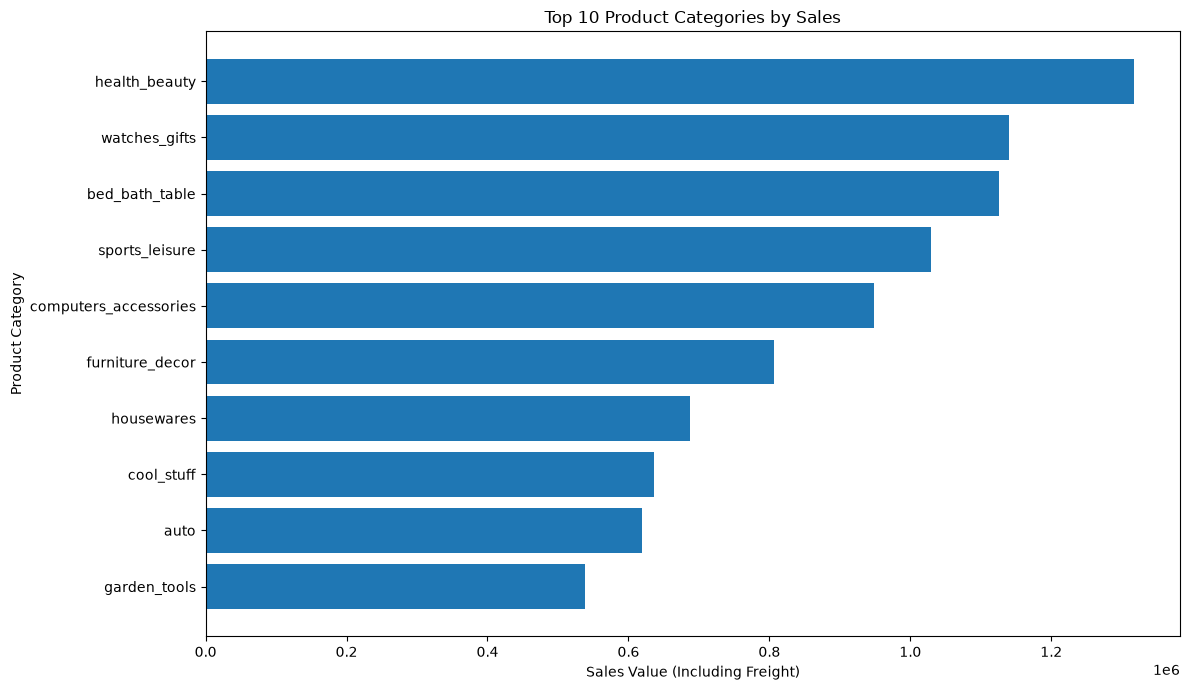

In [60]:
# Step 11: Visualize top 10 product categories by sales

top_categories = category_sales[
    category_sales["product_category_name_english"] != "unknown"
].head(10).sort_values("total_sales")

plt.figure(figsize=(12, 7))

plt.barh(
    top_categories["product_category_name_english"],
    top_categories["total_sales"]
)

plt.title("Top 10 Product Categories by Sales")
plt.xlabel("Sales Value (Including Freight)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [61]:
# Step 12: Compare category sales volume and value per item

category_performance = (
    category_df.groupby("product_category_name_english")
    .agg(
        items_sold=("order_item_id", "count"),
        total_sales=("item_total_value", "sum")
    )
    .reset_index()
)

category_performance["average_value_per_item"] = (
    category_performance["total_sales"]
    / category_performance["items_sold"]
)

# Exclude unknown categories for this comparison
category_performance = category_performance[
    category_performance["product_category_name_english"] != "unknown"
]

# Show categories with the most items sold
top_by_volume = category_performance.sort_values(
    "items_sold",
    ascending=False
).head(10)

display(top_by_volume)

,product_category_name_english,items_sold,total_sales,average_value_per_item
7,bed_bath_table,10101,"1,125,740.89",111.45
43,health_beauty,8882,"1,316,839.10",148.26
66,sports_leisure,7819,"1,028,951.13",131.60
39,furniture_decor,7481,"806,289.97",107.78
15,computers_accessories,7182,"948,878.78",132.12
49,housewares,6319,"687,852.98",108.85
72,watches_gifts,5497,"1,140,424.00",207.46
69,telephony,4165,"347,530.22",83.44
42,garden_tools,4139,"538,887.18",130.20
5,auto,3850,"618,762.30",160.72


In [62]:
# Step 13: Prepare order-level delivery analysis

delivery_df = (
    df.groupby("order_id", as_index=False)
    .agg(
        order_status=("order_status", "first"),
        purchase_date=("order_purchase_timestamp", "first"),
        delivered_date=("order_delivered_customer_date", "first"),
        estimated_delivery_date=("order_estimated_delivery_date", "first"),
        delivery_days=("delivery_days", "first"),
        delivery_difference_days=("delivery_difference_days", "first")
    )
)

# Keep successfully delivered orders
delivery_df = delivery_df[
    (delivery_df["order_status"] == "delivered")
    & delivery_df["delivered_date"].notna()
].copy()

print("Delivered orders available for delivery analysis:", len(delivery_df))
display(delivery_df.head())

Delivered orders available for delivery analysis: 94778


,order_id,order_status,purchase_date,delivered_date,estimated_delivery_date,delivery_days,delivery_difference_days
0,00010242fe8c5a6d1ba2dd792cb16214,delivered,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,7.61,-8.01
1,00018f77f2f0320c557190d7a144bdd3,delivered,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,16.22,-2.33
2,000229ec398224ef6ca0657da4fc703e,delivered,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,7.95,-13.44
3,00024acbcdf0a6daa1e931b038114c75,delivered,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,6.15,-5.44
4,00042b26cf59d7ce69dfabb4e55b4fd9,delivered,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,25.11,-15.30


In [63]:
# Step 14: Calculate delivery performance

# Calculate actual delivery time in days
delivery_df["actual_delivery_days"] = (
    delivery_df["delivered_date"] - delivery_df["purchase_date"]
).dt.total_seconds() / (24 * 60 * 60)

# Calculate delivery difference:
# Negative = early, zero = on estimated date, positive = late
delivery_df["delivery_difference_days"] = (
    delivery_df["delivered_date"] - delivery_df["estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)

# Classify delivery performance
delivery_df["delivery_performance"] = np.select(
    [
        delivery_df["delivery_difference_days"] < 0,
        delivery_df["delivery_difference_days"] == 0,
        delivery_df["delivery_difference_days"] > 0
    ],
    [
        "Early",
        "On time",
        "Late"
    ],
    default="Unknown"
)

# Calculate summary metrics
average_delivery_days = delivery_df["actual_delivery_days"].mean()
median_delivery_days = delivery_df["actual_delivery_days"].median()

delivery_counts = delivery_df["delivery_performance"].value_counts()
delivery_percentages = (
    delivery_df["delivery_performance"].value_counts(normalize=True) * 100
)

print("DELIVERY PERFORMANCE SUMMARY")
print("=" * 40)
print(f"Orders analyzed: {len(delivery_df):,}")
print(f"Average delivery time: {average_delivery_days:.2f} days")
print(f"Median delivery time: {median_delivery_days:.2f} days")

print("\nDelivery performance breakdown:")
display(pd.DataFrame({
    "orders": delivery_counts,
    "percentage": delivery_percentages.round(2)
}))

DELIVERY PERFORMANCE SUMMARY
Orders analyzed: 94,778
Average delivery time: 12.56 days
Median delivery time: 10.23 days

Delivery performance breakdown:


,orders,percentage
delivery_performance,,
Early,87091,91.89
Late,7687,8.11


In [64]:
# Step 15: Correct delivery classification using calendar dates

actual_date = delivery_df["delivered_date"].dt.normalize()
estimated_date = delivery_df["estimated_delivery_date"].dt.normalize()

delivery_df["delivery_difference_days"] = (
    actual_date - estimated_date
).dt.days

delivery_df["delivery_performance"] = np.select(
    [
        delivery_df["delivery_difference_days"] < 0,
        delivery_df["delivery_difference_days"] == 0,
        delivery_df["delivery_difference_days"] > 0
    ],
    ["Early", "On time", "Late"],
    default="Unknown"  # Fix: use a string, not the default integer 0
)

delivery_summary = (
    delivery_df["delivery_performance"]
    .value_counts()
    .reindex(["Early", "On time", "Late"], fill_value=0)
    .rename("orders")
    .to_frame()
)

delivery_summary["percentage"] = (
    delivery_summary["orders"] / len(delivery_df) * 100
).round(2)

display(delivery_summary)

,orders,percentage
delivery_performance,,
Early,87091,91.89
On time,1264,1.33
Late,6423,6.78


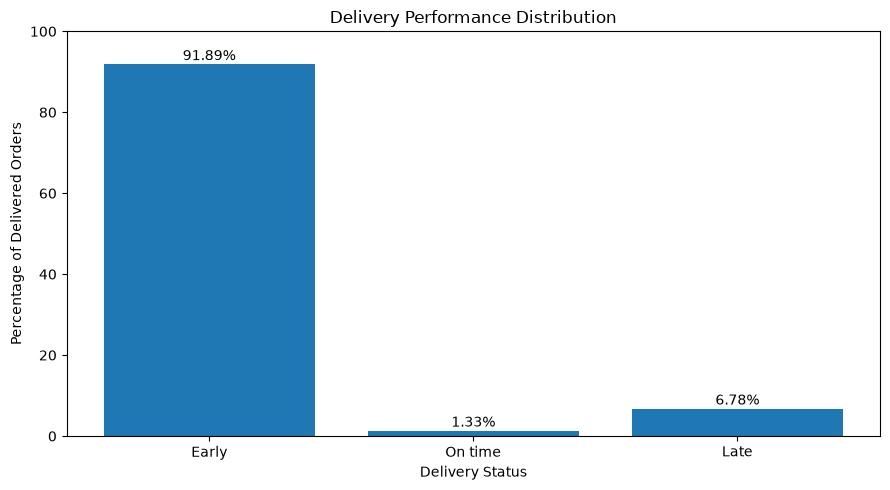

In [65]:
# Step 17: Visualize delivery performance

plt.figure(figsize=(9, 5))

plt.bar(
    delivery_summary.index,
    delivery_summary["percentage"]
)

plt.title("Delivery Performance Distribution")
plt.xlabel("Delivery Status")
plt.ylabel("Percentage of Delivered Orders")
plt.ylim(0, 100)

for i, percentage in enumerate(delivery_summary["percentage"]):
    plt.text(
        i,
        percentage + 1,
        f"{percentage:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [66]:
# Step 18: Prepare seller-level delivery analysis

order_seller = (
    df[["order_id", "seller_id"]]
    .dropna()
    .drop_duplicates()
)

seller_delivery = order_seller.merge(
    delivery_df[
        ["order_id", "delivery_performance"]
    ],
    on="order_id",
    how="inner"
)

print("Unique order-seller combinations:", len(seller_delivery))
display(seller_delivery.head())

Unique order-seller combinations: 96058


,order_id,seller_id,delivery_performance
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,Early
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,Early
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,Early
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,Early
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,Early


In [67]:
# Step 19: Seller-level delivery performance

seller_performance = (
    seller_delivery.groupby("seller_id")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=(
            "delivery_performance",
            lambda x: (x == "Late").sum()
        )
    )
    .reset_index()
)

seller_performance["late_delivery_rate"] = (
    seller_performance["late_orders"]
    / seller_performance["total_orders"]
    * 100
)

# Keep sellers with at least 50 delivered orders
reliable_sellers = seller_performance[
    seller_performance["total_orders"] >= 50
].copy()

# Rank by late-delivery rate
top_late_sellers = reliable_sellers.sort_values(
    ["late_delivery_rate", "total_orders"],
    ascending=[False, False]
).head(10)

print("Sellers analyzed:", len(seller_performance))
print("Sellers with at least 50 orders:", len(reliable_sellers))

display(
    top_late_sellers[
        [
            "seller_id",
            "total_orders",
            "late_orders",
            "late_delivery_rate"
        ]
    ].round({"late_delivery_rate": 2})
)

Sellers analyzed: 2916
Sellers with at least 50 orders: 415


,seller_id,total_orders,late_orders,late_delivery_rate
983,54965bbe3e4f07ae045b90b0b8541f52,71,21,29.58
2169,beadbee30901a7f61d031b6b686095ad,64,15,23.44
1889,a49928bcdf77c55c6d6e05e09a9b4ca5,96,21,21.88
1312,712e6ed8aa4aa1fa65dab41fed5737e4,75,16,21.33
78,06a2c3af7b3aee5d69171b0e14f0ee87,389,74,19.02
2671,ea566164622c6b439516ab18062c42cd,50,9,18.00
1122,6039e27294dc75811c0d8a39069f52c0,62,11,17.74
1577,88460e8ebdecbfecb5f9601833981930,246,42,17.07
321,1ca7077d890b907f89be8c954a02686a,108,18,16.67
2402,d20b021d3efdf267a402c402a48ea64b,84,14,16.67


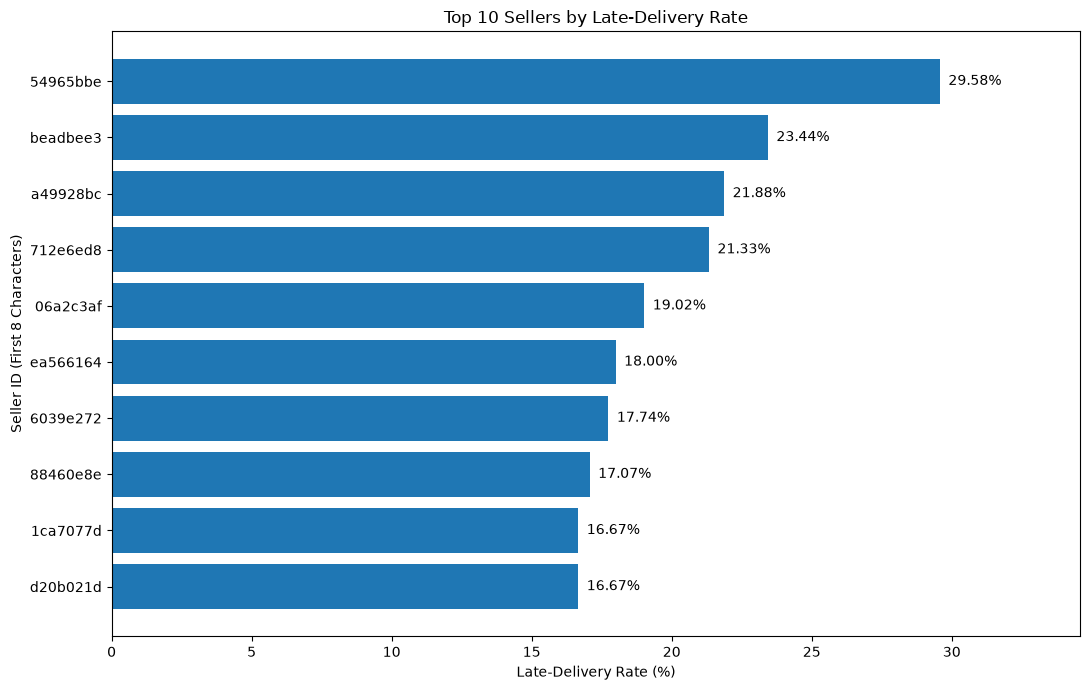

In [68]:
# Step 20: Visualize the top 10 sellers by late-delivery rate

chart_data = top_late_sellers.copy()

chart_data["seller_short_id"] = (
    chart_data["seller_id"].str[:8]
)

chart_data = chart_data.sort_values(
    "late_delivery_rate",
    ascending=True
)

plt.figure(figsize=(11, 7))

bars = plt.barh(
    chart_data["seller_short_id"],
    chart_data["late_delivery_rate"]
)

plt.title("Top 10 Sellers by Late-Delivery Rate")
plt.xlabel("Late-Delivery Rate (%)")
plt.ylabel("Seller ID (First 8 Characters)")

for bar, rate in zip(
    bars,
    chart_data["late_delivery_rate"]
):
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.2f}%",
        va="center"
    )

plt.xlim(
    0,
    chart_data["late_delivery_rate"].max() + 5
)

plt.tight_layout()
plt.show()

In [69]:
# Step 21: Prepare delivery analysis by customer state

state_df = (
    df[["order_id", "customer_state"]]
    .drop_duplicates()
    .merge(
        delivery_df[
            ["order_id", "delivery_performance"]
        ],
        on="order_id",
        how="inner"
    )
)

print("Unique order-state records:", len(state_df))
display(state_df.head())

Unique order-state records: 94778


,order_id,customer_state,delivery_performance
0,00010242fe8c5a6d1ba2dd792cb16214,RJ,Early
1,00018f77f2f0320c557190d7a144bdd3,SP,Early
2,000229ec398224ef6ca0657da4fc703e,MG,Early
3,00024acbcdf0a6daa1e931b038114c75,SP,Early
4,00042b26cf59d7ce69dfabb4e55b4fd9,SP,Early


In [70]:
# Convert date columns back to datetime

date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    df[column] = pd.to_datetime(df[column], errors="coerce")

# Rebuild the order-level delivery dataset

delivery_df = (
    df.groupby("order_id", as_index=False)
    .agg(
        order_status=("order_status", "first"),
        purchase_date=("order_purchase_timestamp", "first"),
        delivered_date=("order_delivered_customer_date", "first"),
        estimated_delivery_date=("order_estimated_delivery_date", "first")
    )
)

delivery_df = delivery_df[
    (delivery_df["order_status"] == "delivered")
    & delivery_df["delivered_date"].notna()
].copy()

# Compare calendar dates, not timestamps

delivery_df["delivery_difference_days"] = (
    delivery_df["delivered_date"].dt.normalize()
    - delivery_df["estimated_delivery_date"].dt.normalize()
).dt.days

delivery_df["delivery_performance"] = np.select(
    [
        delivery_df["delivery_difference_days"] < 0,
        delivery_df["delivery_difference_days"] == 0,
        delivery_df["delivery_difference_days"] > 0
    ],
    ["Early", "On time", "Late"],
    default="Unknown"
)

print("Delivered orders:", len(delivery_df))
display(delivery_df.head())

Delivered orders: 94778


,order_id,order_status,purchase_date,delivered_date,estimated_delivery_date,delivery_difference_days,delivery_performance
0,00010242fe8c5a6d1ba2dd792cb16214,delivered,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,-9,Early
1,00018f77f2f0320c557190d7a144bdd3,delivered,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,-3,Early
2,000229ec398224ef6ca0657da4fc703e,delivered,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,-14,Early
3,00024acbcdf0a6daa1e931b038114c75,delivered,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,-6,Early
4,00042b26cf59d7ce69dfabb4e55b4fd9,delivered,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,-16,Early


In [71]:
# Prepare unique order and customer-state records

state_df = (
    df[["order_id", "customer_state"]]
    .drop_duplicates()
    .merge(
        delivery_df[["order_id", "delivery_performance"]],
        on="order_id",
        how="inner"
    )
)

print("Unique order-state records:", len(state_df))
display(state_df.head())

Unique order-state records: 94778


,order_id,customer_state,delivery_performance
0,00010242fe8c5a6d1ba2dd792cb16214,RJ,Early
1,00018f77f2f0320c557190d7a144bdd3,SP,Early
2,000229ec398224ef6ca0657da4fc703e,MG,Early
3,00024acbcdf0a6daa1e931b038114c75,SP,Early
4,00042b26cf59d7ce69dfabb4e55b4fd9,SP,Early


In [72]:
# Calculate delivery performance by customer state

state_performance = (
    state_df.groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=(
            "delivery_performance",
            lambda x: (x == "Late").sum()
        )
    )
    .reset_index()
)

state_performance["late_delivery_rate"] = (
    state_performance["late_orders"]
    / state_performance["total_orders"]
    * 100
)

state_performance = state_performance.sort_values(
    "late_delivery_rate",
    ascending=False
)

display(state_performance.round({"late_delivery_rate": 2}))

,customer_state,total_orders,late_orders,late_delivery_rate
1,AL,392,84,21.43
9,MA,699,121,17.31
24,SE,334,51,15.27
16,PI,468,66,14.10
5,CE,1261,172,13.64
4,BA,3216,391,12.16
18,RJ,12136,1472,12.13
13,PA,925,105,11.35
7,ES,1954,212,10.85
14,PB,508,52,10.24


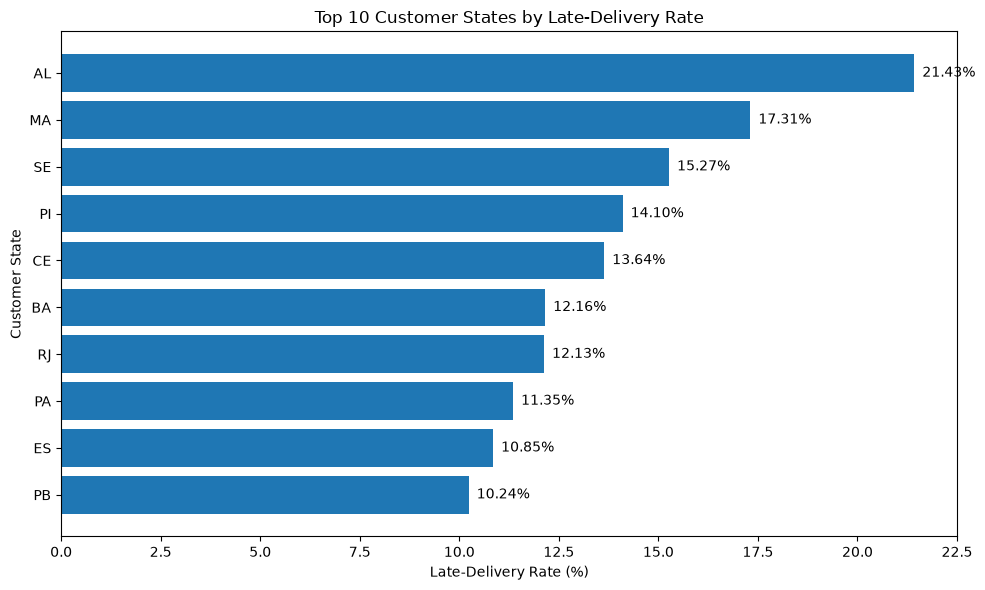

In [73]:
# Step 23: Top 10 states by late-delivery rate

state_chart = (
    state_performance[
        state_performance["total_orders"] >= 300
    ]
    .nlargest(10, "late_delivery_rate")
    .sort_values("late_delivery_rate")
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    state_chart["customer_state"],
    state_chart["late_delivery_rate"]
)

plt.title("Top 10 Customer States by Late-Delivery Rate")
plt.xlabel("Late-Delivery Rate (%)")
plt.ylabel("Customer State")

for bar, rate in zip(bars, state_chart["late_delivery_rate"]):
    plt.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

In [75]:
# Check review-related columns in the master dataset

print([
    column for column in df.columns
    if "review" in column.lower() or "score" in column.lower()
])

['avg_review_score', 'review_count', 'avg_review_response_days']


In [76]:
# Step 24B: Analyze average review scores

review_data = (
    df[["order_id", "avg_review_score"]]
    .dropna(subset=["avg_review_score"])
    .drop_duplicates(subset=["order_id"])
)

print(
    "Overall average review score:",
    round(review_data["avg_review_score"].mean(), 2)
)

score_distribution = (
    review_data["avg_review_score"]
    .round()
    .value_counts()
    .sort_index()
    .rename_axis("review_score")
    .reset_index(name="order_count")
)

score_distribution["percentage"] = (
    score_distribution["order_count"]
    / score_distribution["order_count"].sum()
    * 100
)

display(score_distribution.round({"percentage": 2}))

Overall average review score: 4.1


,review_score,order_count,percentage
0,1.00,10607,11.03
1,2.00,3051,3.17
2,3.00,7950,8.27
3,4.00,18744,19.49
4,5.00,55812,58.04


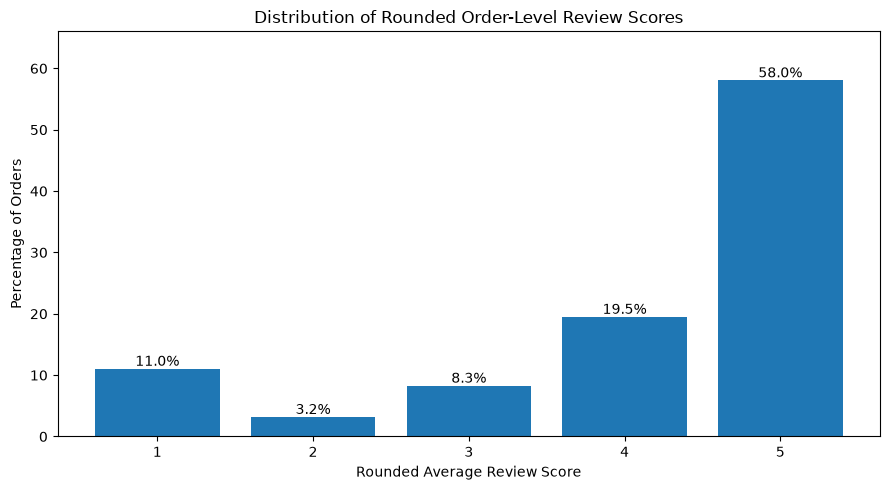

In [77]:
# Step 25: Visualize order-level review scores

plt.figure(figsize=(9, 5))

bars = plt.bar(
    score_distribution["review_score"].astype(int).astype(str),
    score_distribution["percentage"]
)

plt.title("Distribution of Rounded Order-Level Review Scores")
plt.xlabel("Rounded Average Review Score")
plt.ylabel("Percentage of Orders")

for bar, percentage in zip(
    bars, score_distribution["percentage"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{percentage:.1f}%",
        ha="center"
    )

plt.ylim(0, score_distribution["percentage"].max() + 8)
plt.tight_layout()
plt.show()

## Key Business Findings

### 1. Sales Performance
- November 2017 recorded the highest monthly sales in the analyzed delivered-order data.
- Monthly sales were influenced by changes in order volume as well as average order value.

### 2. Product Category Performance
- Bed, bath and table products had the highest item volume among the analyzed categories.
- Health and beauty generated the highest sales value among the listed categories.
- Watches and gifts had a relatively high average value per item.

### 3. Delivery Performance
- Approximately 91.89% of delivered orders arrived before their estimated delivery date.
- Approximately 1.33% arrived on the estimated date, while 6.78% arrived late.

### 4. Seller Performance
- Late-delivery rates varied across sellers.
- Seller comparisons should consider order volume and investigate carrier and geographic factors before attributing responsibility.

### 5. Geographic Performance
- Alagoas had the highest late-delivery rate among the states in the current analysis, at 21.43%.
- São Paulo had the highest number of late deliveries, but its rate was 4.49%.

### 6. Customer Reviews
- The average order-level review score was approximately 4.10 out of 5.
- Rounded order-level average scores were concentrated at 5. These figures should not be interpreted as the exact distribution of individual customer ratings.

### Limitations
- Sales values include freight charges where `item_total_value` was used and should not be interpreted as profit.
- The analysis focuses on recorded historical data and delivered orders for delivery-performance comparisons.
- Observed relationships do not necessarily establish causation.